# 05 · Evaluation

**Goal:** evaluate the matching system the way it would be judged before a firm relies on it: each stage on its own, where it fails and why, whether every decision follows the rules a reviewer would expect, how it holds up when entries are messier, and a fixed set of gates it has to pass.

Everything here uses VAL. TEST and the holdout file are scored once, in the final run (notebook 06), with the same code (`src/evaluate.py` and `src/pipeline.py`) and the same gates, so the criteria are set before the final results exist.

| Piece | Question it answers | Section |
|---|---|---|
| Evaluation sets | What is each set for, and is it the same set next time? | 3 |
| Stage metrics | How well does each step do on its own: extraction, pair model, decisions? | 4 |
| Slices | Which kinds of entries does it handle well or badly? | 5 |
| Error analysis | What goes wrong, how often, and why? | 6 |
| Checks on every decision | Does every decision follow the rules, including its reason? | 7 |
| Stress tests | What happens when entries are messier than the synthetic data? | 8 |
| Gates | Is it good enough on every axis that matters, not just on average? | 9 |
| Saved report | Did a later change make anything worse? | 10 |

**Questions**
1. How well does each stage do on its own?
2. Where does the system fail, and why?
3. Does every decision follow the rules a reviewer would expect?
4. How does it hold up when entries are messier than the synthetic data?
5. Does it pass the gates set for the final run?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer

sys.path.insert(0, "../src")
from rules import ACTIONS, answer_key, score
from fuzzy import client_name_table
from pipeline import load_reference, decide_pairs, score_entries
from evaluate import (parse_metrics, pair_metrics, calibration_error, action_table, headline, slice_table,
                      add_failure_types, FAILURE_TYPES, check_decisions, stress_variants, changed_decisions,
                      check_gates, dataset_hash, compare_reports, GATES, TRACKED)

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
RESULTS_DIR = Path("../results")
SPLIT = "VAL"           # TEST and the holdout file are only scored in the final run
SETTING = "default"     # the chosen cutoffs from notebook 04
METHOD = f"classifier ({SETTING})"
SEED = 210


## 2. Load data

- **Decisions:** the saved VAL decisions from notebook 04 at the chosen setting, with their reasons.
- **Pairs:** the VAL pairs table from notebook 02, scored again by the saved pair model so every candidate has its probability.
- **Entries:** the entries as notebook 00 leaves them (emails parsed), used for the stress tests.

The answer key is only used for scoring. The embedding model is the same one notebook 02 uses.

In [3]:
feature_config = json.loads((RESULTS_DIR / "02_config.json").read_text())
CLIENT_COL, MATTER_COL = feature_config["client_col"], feature_config["matter_col"]

matter_master = pd.read_excel(DATA_PATH, sheet_name="Matter Master", dtype=str)
pairs = pd.read_parquet(RESULTS_DIR / "02_pairs.parquet")
answers = answer_key(pairs)
entries = pd.read_parquet(RESULTS_DIR / "00_entries.parquet")
decisions = pd.read_csv(RESULTS_DIR / "04_decisions.csv", low_memory=False)
scored = decisions[(decisions["method"] == METHOD) & (decisions["split"] == SPLIT)].reset_index(drop=True)

split_ids = set(answers.loc[answers["split"] == SPLIT, "entry_id"])
split_pairs = pairs[pairs["entry_id"].isin(split_ids)].reset_index(drop=True)
split_entries = entries[entries["entry_id"].isin(split_ids)].reset_index(drop=True)
scored = scored.merge(entries[["entry_id", "source_format"]], on="entry_id")
rules_split = pd.read_csv(RESULTS_DIR / "03_decisions.csv", low_memory=False).query("split == @SPLIT")
rules_scored = score(rules_split[["entry_id", "shortlist", "action", "pred_cmid"]], answers)

encoder = SentenceTransformer(feature_config["embedding_model"])
ref = load_reference(DATA_PATH, RESULTS_DIR, encoder, SETTING)
split_pairs, top, _ = decide_pairs(split_pairs, ref)
valid_cmids = set(ref["matters"]["cmid"])

assert set(scored["entry_id"]) == split_ids == set(split_entries["entry_id"])
assert not decisions["split"].isin(["TEST", "HOLDOUT"]).any()
print(f"{SPLIT}: {len(scored)} entries | {len(split_pairs):,} pairs | setting: {SETTING}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

VAL: 601 entries | 61,903 pairs | setting: default


## 3. Evaluation sets

Each set has one job, and none of them is used for another job:

| Set | Job | Entries |
|---|---|---|
| TRAIN | fit models and tune settings, with 5 cross-validation folds | 2,802 |
| VAL | compare versions and choose settings; this notebook | 601 |
| TEST | one final score, after everything is frozen | 597 |
| Holdout file | final check on conditions never seen: new phrasings, a timekeeper with no history, later dates | 800 |
| Stress set | VAL entries changed on purpose (section 8) | VAL x 9 |

**Golden set:** VAL is the fixed set every version is graded on. Each entry carries its entry type (clean, incomplete, messy, wrong CMID, multi-matter, new client, and so on), so every failure type is represented and results can be broken down by it. A short fingerprint of the entry list and answer key is saved with the report, so a changed set can't be mistaken for the same one.

In [4]:
golden = answers[answers["entry_id"].isin(split_ids)][["entry_id", "key_entry_category", "key_expected_action", "key_true_cmid", "key_secondary_cmid"]]
golden = golden.merge(entries[["entry_id", "source_format"]], on="entry_id")
fingerprints = {SPLIT: dataset_hash(golden, list(golden.columns)),
                "TEST ids": dataset_hash(answers[answers["split"] == "TEST"], ["entry_id"])}
print("Fingerprints:", fingerprints)
pd.crosstab(golden["key_entry_category"], golden["source_format"], margins=True)

Fingerprints: {'VAL': '1b45a83afbff', 'TEST ids': 'd21414339749'}


source_format,EMAIL,HANDWRITTEN,PDF,TYPED,All
key_entry_category,,,,,
AMBIGUOUS,9,5,6,18,38
CLEAN,0,29,29,90,148
CLOSED_OR_NOT_OPEN,0,2,2,6,10
INCOMPLETE,21,22,24,79,146
MESSY,20,28,25,54,127
MULTI_NAMED,6,2,4,11,23
MULTI_UNNAMED,2,3,0,9,14
NO_MATCH,9,7,2,19,37
WRONG_CMID_SILENT,0,6,4,22,32


- Every entry type shows up in every source format, though some cells are small (10 to 40 entries), so results for one type in one format are noisy.
- The TEST fingerprint only covers which entries are in it, so the final run can confirm it's the same untouched set.

## 4. Stage by stage

The pipeline has three steps, and each one can fail on its own. Measuring them separately shows which step a failure comes from.

### Extraction: emails

Emails are the one format with nothing in the CMID, client, or matter fields until they're parsed (notebook 00).

In [5]:
emails = split_entries[split_entries["source_format"] == "EMAIL"]
pd.Series(parse_metrics(emails, answers, client_name_table(matter_master, feature_config["acronym_skip"]))).round(3).to_frame(SPLIT)

,VAL
emails,67.000
hours_found,1.000
client_filled,0.701
right_client,0.655
wrong_client,0.052


- Hours are found in every email. The client field is filled for about 7 in 10, and it points to the wrong client for about 1 in 20.
- Emails that never name the client can't be fixed here. They rely on the narrative and the timekeeper's history, like any incomplete entry.

### Step 1: the pair model

- **Top-1 / top-3:** share of entries whose right matter is ranked first or in the top three
- **Calibration error:** for each entry's top pick, the average gap between the predicted probability and how often the pick is right (0 is perfect). It matters because that probability becomes the confidence a reviewer sees. It's measured on top picks only: across all 103 candidates per entry, almost every pair is an obvious no near 0, which makes the error look tiny whatever the model does.

In [6]:
pd.Series(pair_metrics(split_pairs)).round(4).to_frame(SPLIT)

,VAL
entries,601.0000
top_1,0.9309
top_3,0.9840
log_loss,0.0089
calibration_error,0.0501


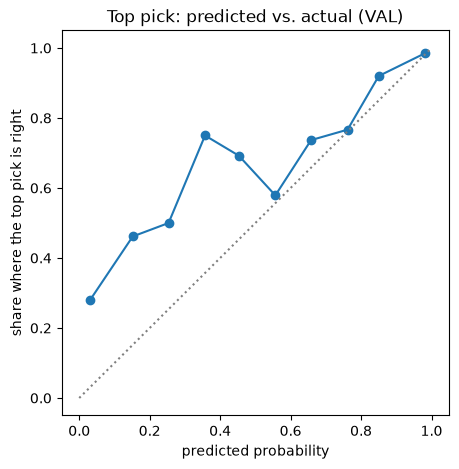

,predicted,actual,entries
prob,,,
"(-0.001, 0.1]",0.032,0.281,32
"(0.1, 0.2]",0.152,0.462,13
"(0.2, 0.3]",0.254,0.500,20
"(0.3, 0.4]",0.357,0.750,8
"(0.4, 0.5]",0.453,0.692,13
"(0.5, 0.6]",0.557,0.579,19
"(0.6, 0.7]",0.658,0.737,19
"(0.7, 0.8]",0.762,0.767,30
"(0.8, 0.9]",0.850,0.920,50


In [7]:
top_picks = split_pairs.loc[split_pairs.groupby("entry_id")["prob"].idxmax()]
bins = pd.cut(top_picks["prob"], np.linspace(0, 1, 11), include_lowest=True)
curve = top_picks.groupby(bins, observed=True).agg(predicted=("prob", "mean"), actual=("is_true_matter", "mean"), entries=("prob", "size"))
ax = curve.plot(x="predicted", y="actual", marker="o", legend=False, figsize=(5, 5), title=f"Top pick: predicted vs. actual ({SPLIT})")
ax.plot([0, 1], [0, 1], linestyle=":", color="gray")
ax.set(xlabel="predicted probability", ylabel="share where the top pick is right")
plt.show()
curve.round(3)

- The right matter is ranked first for about 9 in 10 entries and in the top three for nearly all of them.
- **High-confidence picks match their confidence:** above 0.8, where three quarters of top picks land, the pick is right about as often as its probability says.
- **Low-confidence picks are under-confident:** below 0.5, the top pick is right more often than its probability says, because when every candidate scores low, the best one is still often right. That's the safe direction, but it puts the calibration error at 0.050, right at its gate line (section 9).

### Step 2: decisions

Precision and recall for each action. For actions that suggest a matter, `matter_right` is the share of those calls where the suggested matter is right.

In [8]:
action_table(scored).round(3)

,calls,expected,precision,recall,matter_right
AUTO_MATCH,373.0,453.0,0.887,0.731,0.979
FLAG_MISMATCH,29.0,36.0,0.552,0.444,0.828
NEEDS_REVIEW,133.0,38.0,0.075,0.263,0.669
MULTI_MATTER,50.0,37.0,0.600,0.811,0.540
NO_MATCH,16.0,37.0,0.938,0.405,NaN


In [9]:
pd.Series(headline(scored)).round(3).to_frame(SPLIT)

,VAL
entries,601.000
decided_precision,0.977
ci_low,0.961
ci_high,0.990
straight_through,0.647
review_share,0.221
matter_accuracy,0.865
action_accuracy,0.669
silent_errors,8.000
silent_rate,0.021


- **Auto-matches** are the decisions nobody checks, so their matter accuracy is what counts: 98% have the right matter.
- **`NEEDS_REVIEW` has low precision on purpose:** it's where uncertain entries go, so many entries the answer key would auto-match land there instead. That costs review time, not mistakes.
- **New-client calls** are almost always right (94%), but only about 4 in 10 new clients get the call at this setting. The rest go to review, which is safe. The new-client cutoff is the least stable setting (notebook 04, section 7), so this share can move when the model is refit.

## 5. Slices

One overall number can hide a weak spot, so the same numbers are broken down by source format and by entry type.

In [10]:
cols = ["entries", "decided_precision", "straight_through", "review_share", "silent_errors", "matter_accuracy"]
by_format = slice_table(scored, "source_format")
by_format[cols].round(3)

,entries,decided_precision,straight_through,review_share,silent_errors,matter_accuracy
EMAIL,67.0,0.941,0.507,0.328,1.0,0.746
HANDWRITTEN,109.0,0.986,0.642,0.275,1.0,0.862
PDF,99.0,0.955,0.677,0.182,3.0,0.879
TYPED,326.0,0.986,0.669,0.193,3.0,0.887


In [11]:
by_type = slice_table(scored, "key_entry_category")
by_type[cols].round(3)

,entries,decided_precision,straight_through,review_share,silent_errors,matter_accuracy
AMBIGUOUS,38.0,0.926,0.711,0.263,1.0,0.921
CLEAN,148.0,1.000,0.797,0.176,0.0,1.000
CLOSED_OR_NOT_OPEN,10.0,1.000,0.700,0.000,0.0,0.900
INCOMPLETE,146.0,1.000,0.760,0.192,0.0,0.959
MESSY,127.0,1.000,0.701,0.252,0.0,0.976
MULTI_NAMED,23.0,0.000,0.130,0.174,3.0,0.043
MULTI_UNNAMED,14.0,NaN,0.000,0.000,0.0,0.786
NO_MATCH,37.0,1.000,0.405,0.541,0.0,0.405
WRONG_CMID_SILENT,32.0,0.692,0.406,0.188,4.0,0.625
WRONG_CMID_TEXT,26.0,1.000,0.231,0.269,0.0,0.654


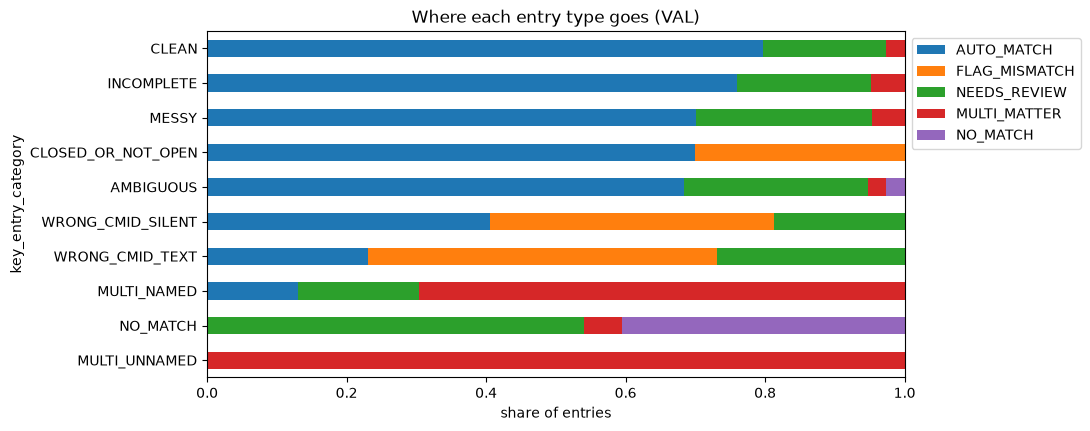

In [12]:
where = pd.crosstab(scored["key_entry_category"], scored["action"], normalize="index")[ACTIONS]
ax = where.sort_values("AUTO_MATCH").plot.barh(stacked=True, figsize=(9, 4.5), xlim=(0, 1), title=f"Where each entry type goes ({SPLIT})")
ax.set_xlabel("share of entries")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

- **By format:** typed and handwritten entries do best (99% decided precision), then PDFs (96%). Emails are decided automatically least often (51%) and have the lowest decided precision (94%), but they're also the smallest slice, so a single mistake moves them a lot.
- **By entry type:** clean, incomplete, and messy entries are right whenever they're decided automatically. The 8 silent errors are 4 wrong CMIDs that nothing in the entry contradicts, 3 named multi-matter entries accepted as one matter, and 1 ambiguous entry.
- **Typed-CMID corrections:** 6 of 26 wrong-CMID entries whose narrative points elsewhere and 7 of 10 closed-matter entries are auto-matched by correcting the typed CMID, all to the right matter. The rest are flagged or sent to review.
- **Wrong CMIDs that nothing openly contradicts** (32): 9 are corrected to the right matter, 13 are flagged, 6 go to review, and 4 end up as silent errors (3 accepted as typed, 1 corrected to the wrong matter).

## 6. Error analysis

Each decision is checked against the answer key and given the first failure type that applies (`add_failure_types` in `src/evaluate.py`). The types are ordered by cost: a silent error goes on the bill unchecked, while an extra review only costs a reviewer a few seconds.

In [13]:
scored = add_failure_types(scored)
failures = scored["failure_type"].value_counts().rename("entries").to_frame()
failures["meaning"] = failures.index.map(FAILURE_TYPES)
failures

,entries,meaning
failure_type,,
"review, top pick right",89,"sent to review, but the top pick was right (ex..."
false multi-matter alarm,20,"called multi-matter, but covers one matter"
silent error,8,"accepted with no review, but the matter is wrong"
wrong flag suggestion,5,"flagged, but the suggested matter is wrong"
"review, right matter not in shortlist",4,"sent to review, and the right matter isn't in ..."
missed second matter,4,"covers two matters, but wasn't called multi-ma..."
wrong new-client call,1,"sent to intake as a new client or matter, but ..."


In [14]:
pd.crosstab(scored["failure_type"], scored["key_entry_category"])

key_entry_category,AMBIGUOUS,CLEAN,CLOSED_OR_NOT_OPEN,INCOMPLETE,MESSY,MULTI_NAMED,NO_MATCH,WRONG_CMID_SILENT,WRONG_CMID_TEXT
failure_type,,,,,,,,,
false multi-matter alarm,1,4,0,7,6,0,2,0,0
missed second matter,0,0,0,0,0,4,0,0,0
"review, right matter not in shortlist",0,0,0,1,0,0,0,2,1
"review, top pick right",10,26,0,23,30,0,0,0,0
silent error,1,0,0,0,0,3,0,4,0
wrong flag suggestion,0,0,1,0,0,0,0,2,2
wrong new-client call,1,0,0,0,0,0,0,0,0


- **Most failures are extra work, not errors:** the biggest group (89) is entries sent to review whose top pick was already right. They're spread across clean, incomplete, and messy entries, so a reviewer usually just confirms the first suggestion.
- **Silent errors are rare** (8), and they're wrong CMIDs and named multi-matter entries.
- **Multi-matter mistakes go both ways:** 4 named multi-matter entries are missed, and 20 one-matter entries get a false alarm (mostly block-billed ones).
- **Wrong flag suggestions** come from wrong-CMID and closed-matter entries: the flag is right, but the matter it suggests isn't.

In [15]:
cols = ["entry_id", "source_format", "key_entry_category", "action", "pred_cmid", "key_true_cmid", "reason_short"]
scored.loc[scored["failure_type"] == "silent error", cols]

,entry_id,source_format,key_entry_category,action,pred_cmid,key_true_cmid,reason_short
105,T-00625,PDF,MULTI_NAMED,AUTO_MATCH,7222.002,7222.002,Typed CMID matches
132,T-00814,EMAIL,AMBIGUOUS,AUTO_MATCH,9140.001,5524.001,Reads like past entries
216,T-01348,PDF,WRONG_CMID_SILENT,AUTO_MATCH,9140.001,2215.001,Typed CMID corrected
295,T-01867,TYPED,WRONG_CMID_SILENT,AUTO_MATCH,7215.005,7215.003,Typed CMID matches
318,T-02026,HANDWRITTEN,MULTI_NAMED,AUTO_MATCH,5524.001,5524.001,Typed CMID matches
488,T-03325,PDF,WRONG_CMID_SILENT,AUTO_MATCH,3120.001,4471.004,Typed CMID matches
516,T-03461,TYPED,WRONG_CMID_SILENT,AUTO_MATCH,8340.001,7215.003,Typed CMID matches
531,T-03537,TYPED,MULTI_NAMED,AUTO_MATCH,7222.002,5531.001,Typed CMID corrected


## 7. Checks on every decision

Rules every decision should follow, checked one by one (`check_decisions`). These run on every output, so a broken rule is caught even when the overall numbers look fine.

- A suggested matter has to exist in Matter Master.
- An auto-matched matter has to be open on the work date.
- An auto-match against a valid typed CMID that points elsewhere has to say it corrected the typed CMID.
- A `NO_MATCH` call suggests no matter.
- Every decision has a short and a full reason.
- An auto-match's short reason has to be true for that entry (if it says "Typed CMID matches", the typed CMID really is that matter).
- The stated confidence (high, medium, low) has to match the top pick's probability.
- A review shortlist has three different matters.

In [16]:
checks = check_decisions(scored, split_pairs, valid_cmids, CLIENT_COL, MATTER_COL, feature_config["phrase_min"])
checks

,entries_checked,violations,examples
check,,,
suggested matters exist in Matter Master,601,0,
auto-matched matter was open on the work date,601,0,
auto-match against a valid typed CMID says it corrected it,601,0,
NO_MATCH suggests no matter,601,0,
every decision has a reason,601,0,
auto-match reason is true for that entry,601,0,
stated confidence matches the probability,601,0,
review shortlist has 3 different matters,601,0,


- **No decision breaks a rule.** The reasons only cite clues that are actually there for that entry, every corrected CMID says so, and the confidence label always matches the probability.

### Reproducibility

`src/pipeline.py` runs the saved models end to end on entries it hasn't seen, which is what the final run and the stress tests use. Before trusting it, its decisions on the clean entries are compared with notebook 04's.

In [17]:
_, _, rerun = score_entries(split_entries, ref)
same = rerun.merge(scored[["entry_id", "action", "pred_cmid"]], on="entry_id", suffixes=("", "_04"))
same_action = same["action"] == same["action_04"]
print(f"Same decision as notebook 04: {same_action.sum()} of {len(same)} | same suggested matter: {(same['pred_cmid'].fillna('') == same['pred_cmid_04'].fillna('')).sum()} of {len(same)}")
same.loc[~same_action, ["entry_id", "action", "action_04"]]

Same decision as notebook 04: 601 of 601 | same suggested matter: 601 of 601


,entry_id,action,action_04


- The pipeline gives the same decision and suggested matter as notebook 04 for all 601 entries. On another machine, an entry or two sitting right at a cutoff could tip because of tiny rounding differences in the embeddings.

## 8. Stress tests

The synthetic entries are cleaner than real ones, so each VAL entry is changed on purpose and run through the whole pipeline again (`stress_variants`). Each change tests one kind of messiness:

| Change | What it imitates |
|---|---|
| upper case narrative, extra spaces | formatting that shouldn't change anything |
| OCR noise | a scan or handwriting misread (0 for O, l for 1, rn for m) on 10% of the letters it could hit |
| typo in client name, typo in narrative | a slip while typing |
| CMID digits swapped | "6103.004" typed as "6013.004" |
| CMID left blank, client left blank | missing fields |
| new timekeeper | someone with no billing history, like a lateral hire |

The first two should change nothing. The rest should make things harder, and a good system responds by sending more to review, not by making more silent errors.

In [18]:
variants = stress_variants(split_entries, seed=SEED)
base = score(rerun, answers)
stress, changed = {"clean": headline(base)}, {"clean": 0.0}
for name, changed_entries in variants.items():
    _, _, out = score_entries(changed_entries, ref)
    stress[name] = headline(score(out, answers))
    changed[name] = changed_decisions(rerun, out)
stress = pd.DataFrame(stress).T.assign(changed=pd.Series(changed))
stress[["decided_precision", "ci_low", "straight_through", "review_share", "silent_errors", "matter_accuracy", "changed"]].round(3)

,decided_precision,ci_low,straight_through,review_share,silent_errors,matter_accuracy,changed
clean,0.977,0.961,0.647,0.221,8.0,0.865,0.000
"same, upper case narrative",0.977,0.961,0.647,0.221,8.0,0.865,0.000
"same, extra spaces",0.977,0.961,0.647,0.221,8.0,0.865,0.000
OCR noise (10% of letters),0.969,0.952,0.597,0.253,10.0,0.855,0.173
typo in client name,0.974,0.961,0.651,0.233,9.0,0.867,0.048
typo in narrative,0.973,0.955,0.611,0.258,8.0,0.855,0.148
CMID digits swapped,0.960,0.943,0.586,0.344,9.0,0.844,0.205
CMID left blank,0.960,0.935,0.576,0.296,13.0,0.809,0.233
client left blank,0.950,0.920,0.401,0.358,12.0,0.735,0.381
new timekeeper (no history),0.962,0.944,0.576,0.288,12.0,0.785,0.309


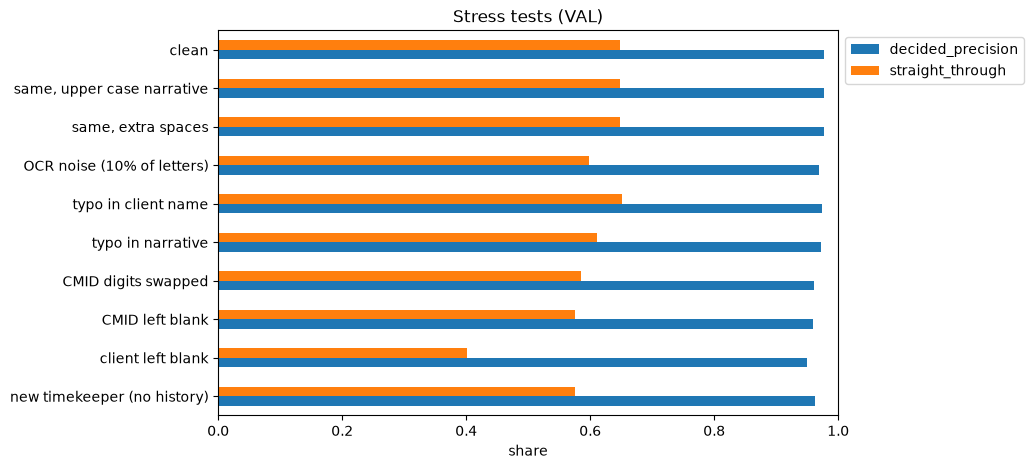

In [19]:
ax = stress.iloc[::-1][["decided_precision", "straight_through"]].plot.barh(figsize=(8, 5), xlim=(0, 1), title=f"Stress tests ({SPLIT})")
ax.set_xlabel("share")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

- **Formatting changes nothing,** as it should: not one decision moves.
- **OCR noise, typos, swapped CMID digits, a blank CMID, and a new timekeeper** keep decided precision between 96% and 97%, and mostly turn into more review.
- **Swapped CMID digits** mostly land on a matter the narrative and history don't back up, so they get flagged or reviewed: review rises from 22% to 34%, with 1 extra silent error.
- **A blank client** costs the most automation (40% decided with no person instead of 65%) and has the lowest precision (95.0%), right at its tracked line, since the client is the strongest clue after the CMID.
- **A new timekeeper** shows how much billing history helps: fewer entries are decided automatically, matter accuracy drops from 87% to 79%, and silent errors rise from 8 to 12.

## 9. Gates

Each gate is one axis that matters on its own, so a gain on one can't hide a loss on another. The lines were set before the final run and live in `src/evaluate.py`, so notebook 06 grades TEST and the holdout file against exactly the same ones. Each one says where it comes from:
- **Principle:** anything else is a bug (a broken rule, a decision changed by formatting).
- **97% target:** follows from the team's chosen setting.
- **Baseline:** the classifier has to beat the rules from notebook 03 on the same entries.
- **Team judgment:** a line picked from what a mistake costs a firm, to be confirmed with billing staff.

**Blockers** have to pass for the system to be used. **Tracked** lines (stress tests and the weakest source format) are reported every run but don't fail it: they show where the system is weakest, and the synthetic changes behind them are cruder than real ones.

In [20]:
rules_results = headline(rules_scored)
results = headline(scored) | pair_metrics(split_pairs) | {
    "rules_decided_precision": rules_results["decided_precision"],
    "rules_silent_errors": rules_results["silent_errors"],
    "violations": int(checks["violations"].sum()),
    "formatting_changed": max(changed["same, upper case narrative"], changed["same, extra spaces"]),
    "stress_worst_precision": float(stress.drop(index="clean")["decided_precision"].min()),
    "format_worst_precision": float(by_format["decided_precision"].min()),
}
gates, tracked = check_gates(results, GATES), check_gates(results, TRACKED)
print(f"Blockers: {gates['passed'].sum()} of {len(gates)} passed | tracked: {tracked['passed'].sum()} of {len(tracked)} at or above their line")
pd.concat({"blocker": gates, "tracked": tracked})

Blockers: 9 of 10 passed | tracked: 2 of 2 at or above their line


value  \
        gate                                            
blocker decided precision, low end of range     0.961   
        silent errors per auto-match            0.021   
        decided precision above the rules       0.961   
        fewer silent errors than the rules      8.000   
        decisions breaking a check              0.000   
        decisions changed by formatting         0.000   
        new-client calls right                  0.938   
        multi-matter entries caught             0.811   
        right matter in review shortlist        0.812   
        top-pick calibration error              0.050   
tracked worst stress test, decided precision    0.950   
        worst source format, decided precision  0.941   

                                                                             rule  \
        gate                                                                        
blocker decided precision, low end of range                               >= 0.95   
        silent errors per auto-match                                      <= 0.03   
        decided precision above the rules       > rules_decided_precision (0.872)   
        fewer silent errors than the rules         < rules_silent_errors (36.000)   
        decisions breaking a check                                           <= 0   
        decisions changed by formatting                                      <= 0   
        new-client calls right                                             >= 0.9   
        multi-matter entries caught                                        >= 0.7   
        right matter in review shortlist                                   >= 0.8   
        top-pick calibration error                                        <= 0.05   
tracked worst stress test, decided precision                              >= 0.95   
        worst source format, decided precision                             >= 0.9   

                                                passed         source  \
        gate                                                            
blocker decided precision, low end of range       True     97% target   
        silent errors per auto-match              True     97% target   
        decided precision above the rules         True       baseline   
        fewer silent errors than the rules        True       baseline   
        decisions breaking a check                True      principle   
        decisions changed by formatting           True      principle   
        new-client calls right                    True  team judgment   
        multi-matter entries caught               True  team judgment   
        right matter in review shortlist          True  team judgment   
        top-pick calibration error               False  team judgment   
tracked worst stress test, decided precision      True     97% target   
        worst source format, decided precision    True  team judgment   

                                                                                              why  
        gate                                                                                       
blocker decided precision, low end of range        the 97% target, allowing for about 600 entries  
        silent errors per auto-match            at most 3 in 100 auto-matches go on the bill w...  
        decided precision above the rules             clearly better than the rules, not by noise  
        fewer silent errors than the rules                   the main reason to replace the rules  
        decisions breaking a check              every decision follows the checks in check_dec...  
        decisions changed by formatting                case and spacing shouldn't change anything  
        new-client calls right                         a wrong call sends a real client to intake  
        multi-matter entries caught              a missed second matter is misbilled or lost time  
        right matter in review shor

- **9 of 10 blockers pass on VAL.** The one that fails is top-pick calibration: 0.0501 against a line of 0.05. The gap is in the safe direction (low-confidence picks are right more often than they say), and the line was a judgment call, so it's reported as a miss rather than moving the line after seeing the result. A calibration step for the confidence a reviewer sees would be the fix if it matters in practice.
- **The baseline gates pass clearly:** the low end of the precision range (96.1%) is well above the rules' 87.2%, and silent errors drop from 36 to 8.
- **Both tracked lines are met:** the worst stress test (client left blank) at 95.0% and the worst format (email) at 94.1%.
- TEST and the holdout file have to pass the same gates in the final run, with no changes in between.

## 10. Save

- `05_eval_report.json`: every number above, the gate results, the setting, and the set fingerprints. A later run is compared with it first, so a change that makes anything worse shows up right away.

In [21]:
report = {"split": SPLIT, "setting": SETTING, "fingerprints": fingerprints, "results": results,
          "gates": gates["passed"].to_dict(), "tracked": tracked["passed"].to_dict(), "stress": stress["decided_precision"].to_dict()}
report_path = RESULTS_DIR / "05_eval_report.json"
if report_path.exists():
    saved = json.loads(report_path.read_text())
    if saved["fingerprints"] == fingerprints and saved["setting"] == SETTING:
        keys = ["decided_precision", "straight_through", "silent_errors", "matter_accuracy", "top_1", "calibration_error"]
        print(compare_reports(results, saved["results"], keys).round(4))
report_path.write_text(json.dumps(report, indent=2, default=float))

print("Saved 05_eval_report.json")

                    saved     now  change
decided_precision  0.9769  0.9769     0.0
straight_through   0.6473  0.6473     0.0
silent_errors      8.0000  8.0000     0.0
matter_accuracy    0.8652  0.8652     0.0
top_1              0.9309  0.9309     0.0
calibration_error  0.0501  0.0501     0.0
Saved 05_eval_report.json


## 11. Findings

- **The system is evaluated stage by stage,** so each failure can be traced to extraction, the pair model, or the decision step.
- **Pair model:** the right matter is ranked first for about 9 in 10 VAL entries and in the top three for nearly all. High-confidence picks are right about as often as they say; low-confidence ones are under-confident, which puts the calibration error right at its line.
- **Decisions:** at the default setting, 97.7% of automatic decisions on VAL are right (range 96.1 to 99.0%) while about 2 in 3 entries are decided with no person. The 8 silent errors are wrong CMIDs and named multi-matter entries.
- **Typed-CMID corrections** catch wrong and closed-matter CMIDs automatically, and nearly all go to the right matter.
- **Slices:** typed, PDF, and handwritten entries do well. Emails trail but are the smallest slice.
- **Error analysis:** most failures are extra review on entries whose top pick was already right, which costs time but no money.
- **Checks:** every decision follows every rule, including that its reason is true for that entry.
- **Stress tests:** formatting changes nothing, and messier input mostly means more review, with precision staying between 95% and 97%.
- **Gates:** 9 of 10 blockers pass on VAL, and both tracked lines are met. Calibration misses its line by a hair, in the safe direction.

## Limitations

- VAL has about 600 entries, so a slice of 30 or 70 entries moves several points with one mistake. The ranges in section 4 say more than the exact numbers, and they resample whole timekeepers, since one person's entries are alike.
- The stress tests change entries with simple rules. Real OCR errors and real typing habits are messier, so these are a floor on how hard real data is, not a ceiling.
- Everything is synthetic, since firms can't share real time entries for privacy reasons. The stress tests and the holdout file's new phrasings are how the system is checked beyond the patterns it was built from.

## Next steps

- If the confidence shown to reviewers needs to be exact, add a calibration step for the top pick's probability.
- Confirm the team-judgment gate lines with billing staff. Typed-CMID corrections were confirmed with the team's legal assistant, as long as the reason shows the CMID was corrected.
- Freeze everything, then run TEST and the holdout file once through the pipeline, these checks, and these gates.